In [ ]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self.grad = 0
        self._backward = lambda : None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += out.grad
            other.grad += out.grad
        out._backward = _backward
        return out
    
    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def backward(self):
        self.grad = 1

        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)

        for v in reversed(topo):
            v._backward()

    def tanh()


a = Value(2)
b = Value(-3)
c = Value(8)

d = a*b + c
d.backward()

print(a.grad, b.grad, c.grad)

-3 2 1


In [9]:
a = Value(2)
b = Value(3)

d = a * b
d.grad = 1

d._backward()

print(a.grad)
print(b.grad)

3
2


In [11]:
a = Value(2)
b = Value(-3)
c = Value(8)

d = a * b + c

d.grad = 1
d._backward()

print(a.grad, b.grad, c.grad)

0 0 1


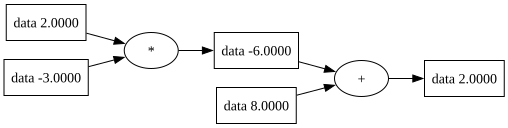

In [3]:
from graphviz import Digraph

def trace(root):
 # builds a set of all nodes and edges in a graph
 nodes, edges = set(), set()
 def build(v):
  if v not in nodes:
   nodes.add(v)
   for child in v._prev:
    edges.add((child, v))
    build(child)
 build(root)
 return nodes, edges

def draw_dot(root):
 dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
 
 nodes, edges = trace(root)
 for n in nodes:
  uid = str(id(n))
  # for any value in the graph, create a rectangular ('record') node for it
  dot.node(name = uid, label = "{ data %.4f }" % (n.data, ), shape='record')
  if n._op:
   # if this value is a result of some operation, create an op node for it
   dot.node(name = uid + n._op, label = n._op)
   # and connect this node to it
   dot.edge(uid + n._op, uid)
   
 for n1, n2 in edges:
  # connect n1 to the op node of n2
  dot.edge(str(id(n1)), str(id(n2)) + n2._op)
  
 return dot


draw_dot(d)
